# data exploration

In [5]:
from __future__ import print_function
import numpy as np
from scipy import stats
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', None)
dataset=pd.read_csv('merged_dataset.csv')


## random info

In [6]:
# dataset.info()

In [7]:
# dataset.head()

In [8]:
# dataset.shape

In [9]:
dataset['label'].value_counts()

label
Pathogenic    5143
Benign        1468
Name: count, dtype: int64

In [10]:
# print(dataset.isna().sum())


In [11]:
df = dataset.dropna()
# print(df.isna().sum())


In [12]:
# df['genename'].value_counts()

In [13]:
# df['genename'].dtype

In [14]:
df = df.astype({col: 'string' for col in df.select_dtypes(include='object').columns})

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6070 entries, 0 to 6672
Data columns (total 33 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   #chr                        6070 non-null   string 
 1   pos(1-based)                6070 non-null   int64  
 2   ref                         6070 non-null   string 
 3   alt                         6070 non-null   string 
 4   aaref                       6070 non-null   string 
 5   aaalt                       6070 non-null   string 
 6   aapos                       6070 non-null   int64  
 7   genename                    6070 non-null   string 
 8   REVEL_score                 6070 non-null   float64
 9   AlphaMissense_score         6070 non-null   float64
 10  CADD_phred                  6070 non-null   float64
 11  ClinPred_score              6070 non-null   float64
 12  BayesDel_addAF_score        6070 non-null   float64
 13  MetaRNN_score               6070 non-n

In [16]:
# df['genename'].dtype

In [17]:
df['label'].value_counts()

label
Pathogenic    4612
Benign        1458
Name: count, dtype: Int64

## data split


![Alternative text for the image](dataset_rules.png)


### General Data (including the other categories)

In [46]:
df_general_all = df

In [47]:
df_general_all['label'].value_counts()

label
Pathogenic    4612
Benign        1458
Name: count, dtype: Int64

### CFTR (cant be used (at leaast for now) due to insuffecient benign data

In [18]:


df_cftr = df[df['genename'].str.contains('CFTR', na=False)]

df_cftr['label'].value_counts()

label
Pathogenic    171
Name: count, dtype: Int64

**we will pass on this**

In [158]:
# df['genename'].value_counts()

### PAH - also cant be used (at leaast for now) due to insuffecient benign data

In [19]:
df_pah = df[df['genename'].str.contains('PAH', na=False)]
df_pah['label'].value_counts()



label
Pathogenic    335
Benign          1
Name: count, dtype: Int64

**we will pass on this**

### Hereditary - data is almost suffecient :)




In [23]:
df_Hereditary = df[df['genename'].str.contains('BRCA1' or ' BRCA2' or ' TP53' or ' PALB2' or ' ATM' or ' CHEK2' or ' MLH1' or ' MSH2' or ' MSH6' or ' PMS2' or ' APC' or ' PTEN' or ' CDH1' or ' STK11' or ' RAD51C' or ' RAD51D' or ' BARD1' or ' BRIP1' or ' VHL' or ' RB1' or ' RET' or ' MEN1' or ' NF1' or ' NF2', na=False)]
df_Hereditary['label'].value_counts()



label
Pathogenic    457
Benign        136
Name: count, dtype: Int64

In [25]:
# df_Hereditary.head()

**we will seperate this (its close eought to the sample size required)**

In [32]:
df_Hereditary.to_csv('modified_data/Hereditary_section.csv', index=False)


### general data without the other categories

In [33]:
indices_to_drop = df_Hereditary.index.union(df_pah.index).union(df_cftr.index)

In [42]:
df_general_no_categories = df.drop(indices_to_drop)

In [40]:
# to check if the cleaning works or nott
dd = df_cleaned[df_cleaned['genename'].str.contains('BRCA1' or ' BRCA2' or ' TP53' or ' PALB2' or ' ATM' or ' CHEK2' or ' MLH1' or ' MSH2' or ' MSH6' or ' PMS2' or ' APC' or ' PTEN' or ' CDH1' or ' STK11' or ' RAD51C' or ' RAD51D' or ' BARD1' or ' BRIP1' or ' VHL' or ' RB1' or ' RET' or ' MEN1' or ' NF1' or ' NF2', na=False)]

# dd.head()

In [43]:
df_general_no_categories.to_csv('modified_data/general_data_no_categories.csv', index=False)


In [26]:
# df.head()

# Graphs

### general data (all included)

In [ ]:
os.makedirs('generated_images', exist_ok=True)


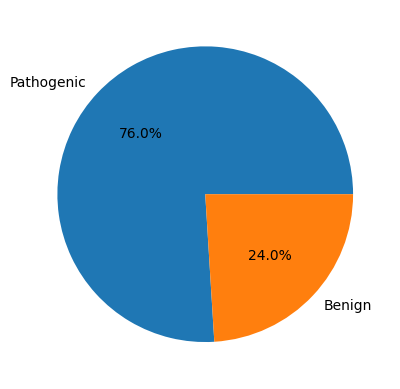

In [184]:
plt.pie(df['label'].value_counts().values,autopct="%1.1f%%",labels=df['label'].value_counts().keys().tolist())
plt.savefig("generated_images/general_data_all.png", dpi=300, bbox_inches='tight')
plt.show()

---

### CFTR

In [165]:
df_cftr['label'].value_counts().keys().tolist()

['Pathogenic']

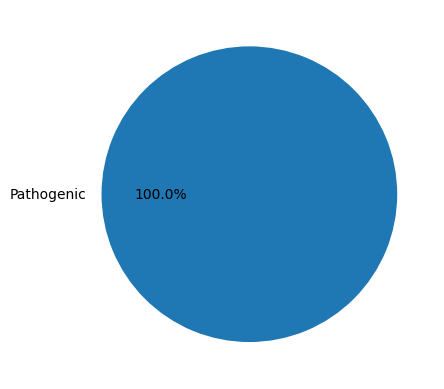

In [183]:
plt.pie(df_cftr['label'].value_counts().values,autopct="%1.1f%%",labels=df_cftr['label'].value_counts().keys().tolist())
plt.savefig("generated_images/CFTR_data.png", dpi=300, bbox_inches='tight')
plt.show()



---

### Hereditary DATA

In [167]:


df_Hereditary['label'].value_counts().keys().tolist()

['Pathogenic', 'Benign']

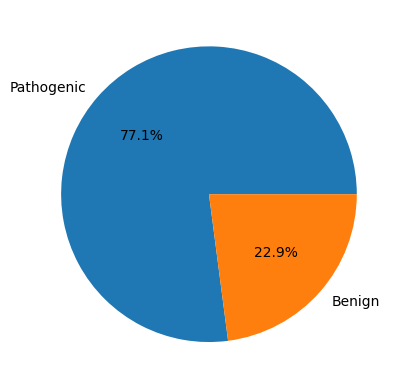

In [185]:
plt.pie(df_Hereditary['label'].value_counts().values,autopct="%1.1f%%",labels=df_Hereditary['label'].value_counts().keys().tolist())

plt.savefig("generated_images/hereditary_data.png", dpi=300, bbox_inches='tight')

plt.show()

### PAH

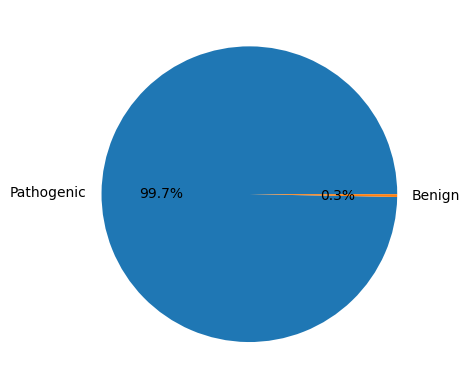

In [189]:
plt.pie(df_pah['label'].value_counts().values,autopct="%1.1f%%",labels=df_pah['label'].value_counts().keys().tolist())
plt.savefig("generated_images/PAH_data.png", dpi=300, bbox_inches='tight')
plt.show()



### correlation

In [ ]:
from sklearn.preprocessing import LabelEncoder

df['label'] = LabelEncoder().fit_transform(df['label'])

In [ ]:
categorical_cols = ['ref', 'alt', 'nuc_before', 'nuc_after', 'ReviewStatus']


# Keep numeric columns separate
numeric_cols = df.drop(columns=categorical_cols + ['label'])

# One-hot encode selected categorical columns
encoded_cats = pd.get_dummies(df[categorical_cols], drop_first=True)

# Combine numeric + encoded categorical columns
X = pd.concat([numeric_cols, encoded_cats], axis=1)

In [ ]:
# Separate target
y = df['label']

# Features
X = df.drop(columns=['label'])

# Encode everything non-numeric
X = pd.get_dummies(X, drop_first=True)

# Final check
print(X.select_dtypes(include=['object', 'string']).columns)

X = pd.get_dummies(df.drop(columns=['label']), drop_first=True)

Index([], dtype='object')


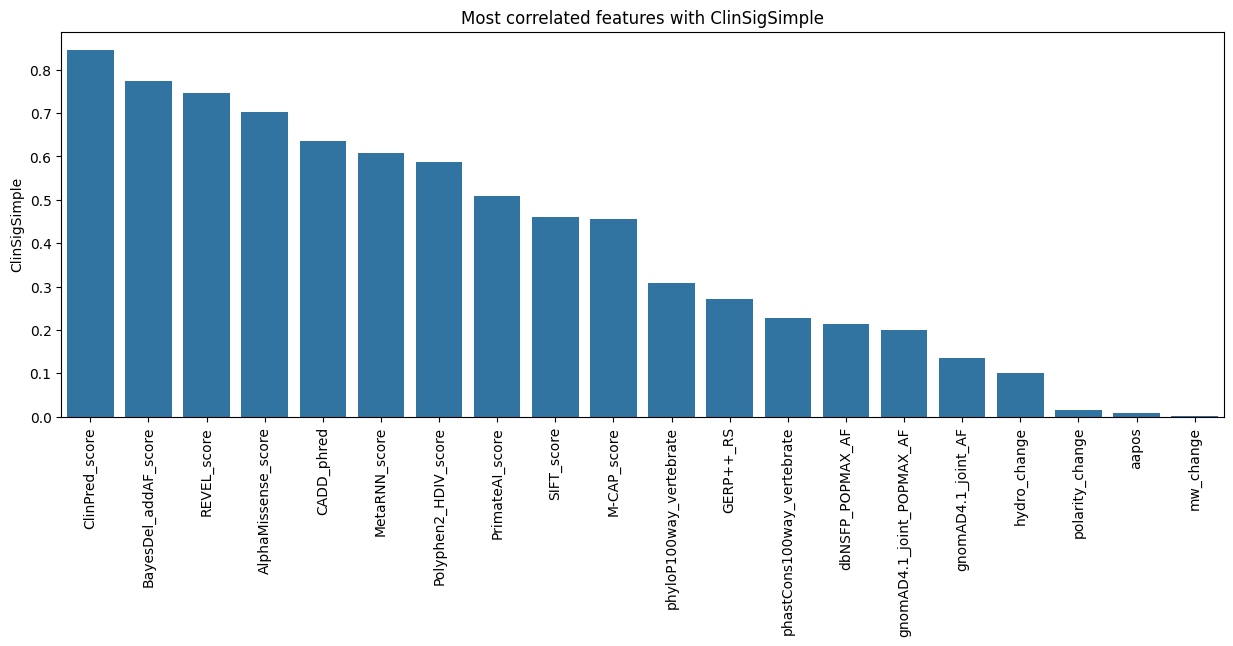

In [179]:



def show_corr(dataset, target_name, n_most=None):
    # Keep only numeric columns
    dataset = dataset.select_dtypes(include='number')

    # Safety check
    if target_name not in dataset.columns:
        raise ValueError(f"{target_name} is not numeric or not in dataset")


    if n_most is None:
        n_most = len(dataset.columns) - 1

    corr_matrix = dataset.corr().abs()

    most_correlated_features = (
        corr_matrix[target_name]
        .sort_values(ascending=False)
        .drop(target_name)
    )

    most_correlated_feature_names = most_correlated_features.index.values

    fig, ax = plt.subplots(figsize=(15, 5))
    plt.xticks(rotation=90)
    sns.barplot(x=most_correlated_feature_names, y=most_correlated_features)
    plt.title(f"Most correlated features with {target_name}")
    plt.savefig(f"generated_images/Most correlated features with {target_name}.png", dpi=300, bbox_inches='tight')

df_num1 = df.drop(['ReviewStatus','genename','pos(1-based)','#chr'],axis=1)
df_num = df_num1.select_dtypes(include='number')
    
show_corr(dataset=df_num, target_name='ClinSigSimple')



### correlation heatmap

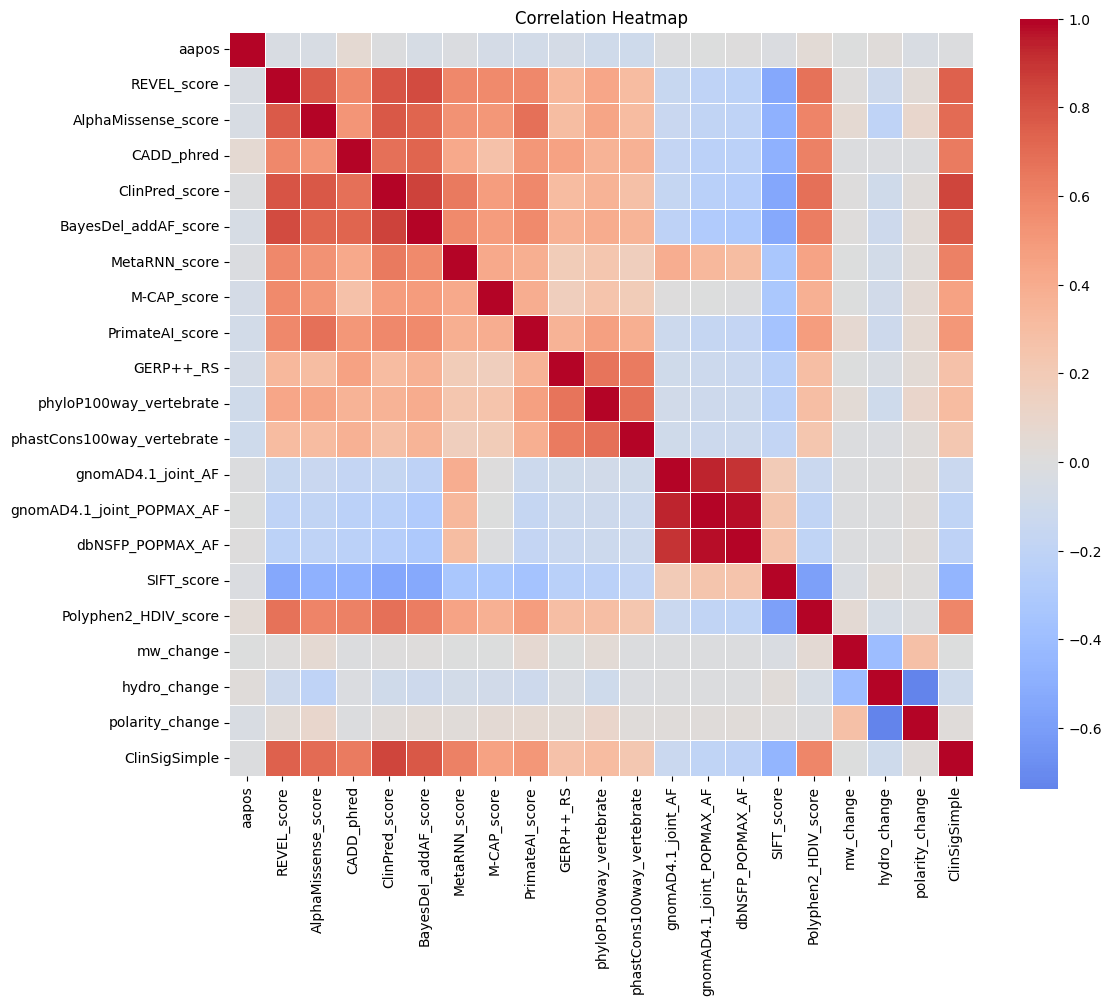

In [182]:
import seaborn as sns
import matplotlib.pyplot as plt

df_num1 = df.drop(['ReviewStatus','genename','pos(1-based)','#chr'],axis=1)
df_num = df_num1.select_dtypes(include='number')

plt.figure(figsize=(12, 10))

corr = df_num.corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)

title = "Correlation Heatmap"
plt.title(title)

plt.savefig(f"generated_images/{title}.png", dpi=300, bbox_inches='tight')

   
plt.show()



---

# Model Training


In [73]:

# y_train.value_counts()




In [55]:
from lazypredict.Supervised import LazyClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import os

datasets_dict = {
    'df_general_all': df_general_all,
    'df_pah':df_pah,
    'df_cftr': df_cftr,
    'df_Hereditary': df_Hereditary,
    'df_general_no_categories': df_general_no_categories
}

os.makedirs('lazy_results', exist_ok=True)
all_models_results = {}
for df_name, dfx in datasets_dict.items():
    print(f"Processing: {df_name}...") 
    
    X = dfx.drop(['ReviewStatus','label','ClinSigSimple','genename','pos(1-based)','#chr'], axis=1)
    y = dfx['label']
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

    clf = LazyClassifier(verbose=1, custom_metric=None)
    models, predictions = clf.fit(X_train, X_test, y_train, y_test)
    
    models.to_csv(f'lazy_results/{df_name}.csv')
    
    all_models_results[df_name] = models
    
    display(models)

Processing: df_general_all...


  0%|          | 0/29 [00:00<?, ?it/s]

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
RandomForestClassifier,0.969522,0.959129,0.993138,0.969578,0.969650,0.969522,0.870002
BaggingClassifier,0.962109,0.955537,0.985317,0.962424,0.963077,0.962109,0.436002
ExtraTreesClassifier,0.966227,0.952036,0.990990,0.966206,0.966187,0.966227,0.331000
AdaBoostClassifier,0.963756,0.951663,0.989092,0.963845,0.963962,0.963756,0.649998
LogisticRegression,0.962109,0.945644,0.989122,0.962062,0.962022,0.962109,0.051000
SVC,0.961285,0.945108,0.984929,0.961261,0.961239,0.961285,0.307001
SGDClassifier,0.957990,0.944198,0.988285,0.958118,0.958290,0.957990,0.054000
Perceptron,0.949753,0.943780,0.984872,0.950423,0.951966,0.949753,0.045000
CalibratedClassifierCV,0.960461,0.943335,0.989255,0.960412,0.960370,0.960461,0.131999


Processing: df_pah...


  0%|          | 0/29 [00:00<?, ?it/s]

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
AdaBoostClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.019996
BaggingClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.032000
DecisionTreeClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.016000
DummyClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.017001
ExtraTreeClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.016000
ExtraTreesClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.111998
SGDClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.016000
GaussianNB,1.000000,1.000000,None,1.000000,1.0,1.000000,0.016000
KNeighborsClassifier,1.000000,1.000000,None,1.000000,1.0,1.000000,0.027002


... (5 outputs left out)

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
BaggingClassifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.043002
DecisionTreeClassifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.019000
LinearDiscriminantAnalysis,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.020998
RidgeClassifierCV,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.019999
QuadraticDiscriminantAnalysis,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.018001
RidgeClassifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.019000
GaussianNB,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.020000
ExtraTreeClassifier,0.991597,0.994681,0.994681,0.991657,0.991920,0.991597,0.017000
AdaBoostClassifier,0.991597,0.980000,1.000000,0.991533,0.991685,0.991597,0.123998


Processing: df_general_no_categories...


  0%|          | 0/29 [00:00<?, ?it/s]

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
RandomForestClassifier,0.965795,0.954367,0.987879,0.965680,0.965653,0.965795,0.712000
BaggingClassifier,0.960765,0.951964,0.976818,0.960786,0.960810,0.960765,0.342004
ExtraTreesClassifier,0.960765,0.950871,0.985590,0.960743,0.960724,0.960765,0.282000
SGDClassifier,0.956740,0.946981,0.985628,0.956764,0.956790,0.956740,0.046000
LogisticRegression,0.959759,0.945800,0.986565,0.959578,0.959551,0.959759,0.043000
LinearSVC,0.959759,0.945800,0.986525,0.959578,0.959551,0.959759,0.044001
AdaBoostClassifier,0.957746,0.945495,0.987162,0.957653,0.957597,0.957746,0.495995
CalibratedClassifierCV,0.957746,0.942216,0.986520,0.957508,0.957509,0.957746,0.117000
SVC,0.955734,0.941910,0.977642,0.955586,0.955524,0.955734,0.231000


# solving imbalance

حتى اللحظة سوينا سكريبت يشتغل على كل الفئات الخاصة بالداتا (وإن كان بعض الفئات غير جاهزة حالياً لكن سويت السكريبت بحيث ينفع بالمستقبل ويسهّل العملية لما تجي الداتا الرسمية)
الآن رح نعيد نفس العملية لكن هالمرة بدنا نعدل مشكلة اتزان الأصناف (خبيث وحميد) للفئات الي عندنا من الداتا
لكن مبدئياً رح نطبقه بس على الداتا الجينيرال وعلى داتا السرطان لان فيهم من الصنفين

Up until now, we have created a script that works on all the data categories (even though some categories aren't ready yet, I built the script so it can be used in the future to simplify the process once the official data arrives). Now, we are going to repeat the same process, but this time we want to fix the class imbalance issue (benign vs. malignant) for the data categories we have. However, for now, we will only apply this to the 'General' data and the 'Cancer' data, as they both contain both classes.



In [60]:
from imblearn.under_sampling import RandomUnderSampler 



datasets_dict = {
    'df_general_all': df_general_all,
    #'df_pah':df_pah,  # These are currently disabled because they only contain one class. هدول معطلين حالياً لان مافيهم غير صنف واحد
    #'df_cftr': df_cftr,  # These are currently disabled because they only contain one class. هدول معطلين حالياً لان مافيهم غير صنف واحد
    'df_Hereditary': df_Hereditary,
    'df_general_no_categories': df_general_no_categories
}

os.makedirs('lazy_results_balanced', exist_ok=True)
all_models_results = {}
for df_name, dfx in datasets_dict.items():
    print(f"Processing: {df_name}...") 
    
    X = dfx.drop(['ReviewStatus','label','ClinSigSimple','genename','pos(1-based)','#chr'], axis=1)
    y = dfx['label']
    
    X_train_raw, X_test, y_train_raw, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    undersampler = RandomUnderSampler(random_state=1)
    
    X_train_resampled, y_train_resampled = undersampler.fit_resample(X_train_raw, y_train_raw)
    
    clf = LazyClassifier(verbose=1, custom_metric=None)
    models, predictions = clf.fit(X_train_resampled, X_test, y_train_resampled, y_test)
    
    models.to_csv(f'lazy_results_balanced/{df_name}.csv')
    
    all_models_results[df_name] = models
    
    display(models)

Processing: df_general_all...


  0%|          | 0/29 [00:00<?, ?it/s]

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
AdaBoostClassifier,0.956343,0.960437,0.989082,0.957200,0.960055,0.956343,0.408996
RandomForestClassifier,0.952224,0.956518,0.992103,0.953235,0.956569,0.952224,0.466000
ExtraTreesClassifier,0.948929,0.954373,0.989769,0.950110,0.954093,0.948929,0.216000
BaggingClassifier,0.946458,0.954000,0.985692,0.947825,0.952654,0.946458,0.196000
CalibratedClassifierCV,0.956343,0.951781,0.989480,0.956878,0.958151,0.956343,0.082000
LinearSVC,0.956343,0.951781,0.989468,0.956878,0.958151,0.956343,0.043000
PassiveAggressiveClassifier,0.943987,0.949917,0.983681,0.945390,0.950101,0.943987,0.042000
SVC,0.953048,0.949635,0.985028,0.953725,0.955435,0.953048,0.162004
SGDClassifier,0.944811,0.949217,0.987676,0.946114,0.950327,0.944811,0.044000


Processing: df_Hereditary...


  0%|          | 0/29 [00:00<?, ?it/s]

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
BernoulliNB,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.018000
ExtraTreesClassifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.095000
SVC,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.020002
RidgeClassifierCV,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.018000
RidgeClassifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.018000
RandomForestClassifier,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.130000
LinearDiscriminantAnalysis,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.016999
NuSVC,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.022000
BaggingClassifier,0.991597,0.994681,0.999787,0.991657,0.991920,0.991597,0.038000


Processing: df_general_no_categories...


  0%|          | 0/29 [00:00<?, ?it/s]

,Accuracy,Balanced Accuracy,ROC AUC,F1 Score,Precision,Recall,Time Taken
Model,,,,,,,
CalibratedClassifierCV,0.958753,0.952751,0.986881,0.958907,0.959174,0.958753,0.074002
LinearSVC,0.958753,0.952751,0.986786,0.958907,0.959174,0.958753,0.037002
LogisticRegression,0.954728,0.949954,0.986621,0.954990,0.955530,0.954728,0.038998
BaggingClassifier,0.944668,0.948425,0.978352,0.945511,0.948447,0.944668,0.187999
RandomForestClassifier,0.946680,0.947638,0.988177,0.947349,0.949396,0.946680,0.412000
LinearDiscriminantAnalysis,0.958753,0.947287,0.986255,0.958684,0.958637,0.958753,0.039000
RidgeClassifier,0.958753,0.947287,0.986280,0.958684,0.958637,0.958753,0.038001
RidgeClassifierCV,0.958753,0.947287,0.986245,0.958684,0.958637,0.958753,0.047998
AdaBoostClassifier,0.945674,0.946938,0.986094,0.946380,0.948573,0.945674,0.329999
